#### Auto ENcoders

In [57]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [58]:
# Set random seed
np.random.seed(42)
torch.manual_seed(42)

# 1000 records of 20 normalized government service metrics
dummy_data = np.random.rand(1000, 20)

# Convert NumPy array into PyTorch tensor
X = torch.tensor(dummy_data, dtype=torch.float32)

print(X.shape)

torch.Size([1000, 20])


In [59]:
X

tensor([[0.3745, 0.9507, 0.7320,  ..., 0.5248, 0.4319, 0.2912],
        [0.6119, 0.1395, 0.2921,  ..., 0.0977, 0.6842, 0.4402],
        [0.1220, 0.4952, 0.0344,  ..., 0.1960, 0.0452, 0.3253],
        ...,
        [0.0920, 0.5754, 0.9781,  ..., 0.8772, 0.4143, 0.5021],
        [0.5221, 0.1941, 0.6895,  ..., 0.2435, 0.0900, 0.4421],
        [0.8900, 0.4675, 0.8497,  ..., 0.3037, 0.4433, 0.1723]])

In [60]:
class AutoEncoder(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder: 20 -> 100 -> 10 -> 5
        self.encoder = nn.Sequential(
            nn.Linear(X.shape[1], 1000),
            nn.ReLU(),

            nn.Linear(1000, 100),
            nn.ReLU(),

            nn.Linear(100, 5),
            nn.ReLU()
        )

        # Decoder: 5 -> 100 -> 1000 -> 20
        self.decoder = nn.Sequential(
            nn.Linear(5, 100),
            nn.ReLU(),

            nn.Linear(100, 1000),
            nn.ReLU(),

            nn.Linear(1000, X.shape[1]),
            nn.Sigmoid()
        )

    def forward(self, x):

        latent_space = self.encoder(x)

        reconstructed = self.decoder(latent_space)

        return reconstructed


autoencoder = AutoEncoder()

print(autoencoder)

AutoEncoder(
  (encoder): Sequential(
    (0): Linear(in_features=20, out_features=1000, bias=True)
    (1): ReLU()
    (2): Linear(in_features=1000, out_features=100, bias=True)
    (3): ReLU()
    (4): Linear(in_features=100, out_features=5, bias=True)
    (5): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=5, out_features=100, bias=True)
    (1): ReLU()
    (2): Linear(in_features=100, out_features=1000, bias=True)
    (3): ReLU()
    (4): Linear(in_features=1000, out_features=20, bias=True)
    (5): Sigmoid()
  )
)


In [61]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

# Move model and data to GPU
autoencoder = autoencoder.to(device)
X = X.to(device)

# Define loss function and optimizer
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=0.001)

Using device: cuda
GPU Name: NVIDIA GeForce RTX 3050 OEM


In [62]:
epochs = 1000
loss_history = []

for epoch in range(epochs):

    autoencoder.train()

    # Forward pass
    reconstructed = autoencoder(X)

    # Calculate reconstruction loss
    loss = loss_fn(reconstructed, X)

    # Reset gradients
    optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Update weights
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(f"Epoch: {epoch+1}/{epochs} | Loss: {loss.item():.6f}")

Epoch: 100/1000 | Loss: 0.066923
Epoch: 200/1000 | Loss: 0.062072
Epoch: 300/1000 | Loss: 0.057666
Epoch: 400/1000 | Loss: 0.053763
Epoch: 500/1000 | Loss: 0.050417
Epoch: 600/1000 | Loss: 0.047167
Epoch: 700/1000 | Loss: 0.044620
Epoch: 800/1000 | Loss: 0.042977
Epoch: 900/1000 | Loss: 0.040874
Epoch: 1000/1000 | Loss: 0.039697


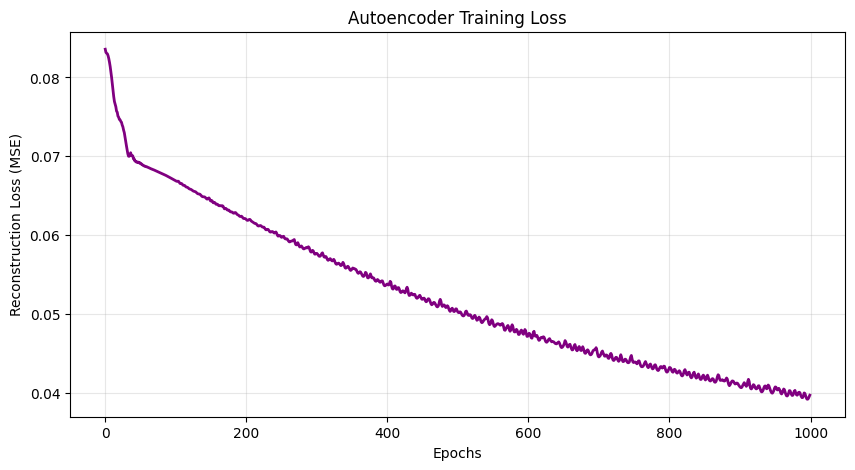

In [63]:
plt.figure(figsize=(10, 5))

plt.plot(loss_history, color="purple", linewidth=2)

plt.title("Autoencoder Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Reconstruction Loss (MSE)")
plt.grid(alpha=0.3)
plt.show()

In [64]:
autoencoder.eval()

with torch.inference_mode():

    compressed_data = autoencoder.encoder(X)

    reconstructed_data = autoencoder(X)

print("Original data:", X.shape)
print("Compressed data:", compressed_data.shape)
print("Reconstructed data:", reconstructed_data.shape)

Original data: torch.Size([1000, 20])
Compressed data: torch.Size([1000, 5])
Reconstructed data: torch.Size([1000, 20])


In [65]:
autoencoder.eval()

with torch.inference_mode():

    original = X[0:1]

    compressed = autoencoder.encoder(original)

    decompressed = autoencoder.decoder(compressed)

print("Original Data (20 features):")
print(original.cpu().numpy().round(4))

print("\nCompressed Data (5 features):")
print(compressed.cpu().numpy().round(4))

print("\nDecompressed Data (20 features):")
print(decompressed.cpu().numpy().round(4))

Original Data (20 features):
[[0.3745 0.9507 0.732  0.5987 0.156  0.156  0.0581 0.8662 0.6011 0.7081
  0.0206 0.9699 0.8324 0.2123 0.1818 0.1834 0.3042 0.5248 0.4319 0.2912]]

Compressed Data (5 features):
[[4.0982 0.     1.559  0.     1.8701]]

Decompressed Data (20 features):
[[0.5369 0.6533 0.7792 0.5327 0.265  0.4263 0.4644 0.796  0.6717 0.6525
  0.2957 0.5719 0.6921 0.4823 0.3556 0.4597 0.5311 0.7197 0.2143 0.4693]]


In [66]:
plt.figure(figsize=(12, 5))

plt.plot(
    original.flatten().numpy(),
    marker='o',
    color='blue',
    label='Original Data'
)

plt.plot(
    decompressed.flatten().numpy(),
    marker='s',
    color='red',
    linestyle='--',
    label='Decompressed Data'
)

plt.title("Original vs Reconstructed Data")
plt.xlabel("Feature Index")
plt.ylabel("Feature Value")
plt.xticks(range(20))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

TypeError: can't convert cuda:0 device type tensor to numpy. Use Tensor.cpu() to copy the tensor to host memory first.

<Figure size 1200x500 with 0 Axes>

In [ ]:
total_params = sum(
    p.numel() for p in autoencoder.parameters()
    if p.requires_grad
)

print("Total trainable parameters:", total_params)

Total trainable parameters: 243225
